# Flappy Bird: Double Dueling DQN
Hai chế độ quan sát: `pixel` (CNN) và `state` (MLP). Mã nguồn nằm trong `flappy_rl/`.

Mọi kết quả của một lần chạy nằm trong `flappy_bird_output/<mode>_<thời gian>/`
(trên Colab là `My Drive/flappy_bird_output/`, nên mất kết nối vẫn còn checkpoint):

| File | Nội dung |
|---|---|
| `config.json` | cấu hình agent và train |
| `best.pt`, `last.pt` | checkpoint tốt nhất (theo điểm greedy) và mới nhất |
| `progress.csv`, `history.json` | log huấn luyện |
| `training_results.png` | đồ thị |
| `holdout.json`, `gameplay.mp4` | đánh giá cuối và video |
| `replay.json`, `weights.json`, `viewer.html` | giao diện 3D |

In [1]:
import importlib.util
import subprocess
import sys
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/flappy_bird.zip")  # zip nằm ngay trong My Drive
PROJECT = Path("/content/flappy_bird")

if importlib.util.find_spec("flappy_rl") is None:  # chạy trên Colab: giải nén dự án từ Drive rồi cài
    from google.colab import drive
    drive.mount("/content/drive")
    if not ZIP_PATH.exists():  # dự phòng: tìm flappy_bird.zip ở bất kỳ đâu trong My Drive
        found = sorted(Path("/content/drive/MyDrive").rglob("flappy_bird.zip"))
        if not found:
            raise FileNotFoundError("Không tìm thấy flappy_bird.zip trong My Drive")
        ZIP_PATH = found[0]
    print("Dùng:", ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(PROJECT)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-e", str(PROJECT)])
    sys.path.insert(0, str(PROJECT))  # kernel đang chạy chưa thấy gói vừa cài editable

Mounted at /content/drive
Dùng: /content/drive/MyDrive/flappy_bird.zip


## Cấu hình
- `MODE`: `"state"` học nhanh (khoảng 1 triệu bước), `"pixel"` học từ ảnh nên chậm hơn nhiều (2 triệu bước).
- `RESUME_DIR`: để trống khi train mới. Muốn train tiếp sau khi Colab ngắt, dán đường dẫn thư mục
  của lần chạy cũ (ví dụ `/content/drive/MyDrive/flappy_bird_output/pixel_20261029_071937`);
  agent nạp `last.pt`, ghi tiếp vào đúng thư mục đó.
- `TOTAL_STEPS`: `None` dùng mặc định của chế độ; đặt số nhỏ (ví dụ `50_000`) để chạy thử.

In [2]:
import json

from flappy_rl import AgentConfig, DQNAgent, TrainConfig
from flappy_rl.envs import make_env
from flappy_rl.runtime import new_run_dir, resolve_device, set_seed
from flappy_rl.training import History

MODE = "pixel"          # "pixel" hoặc "state"
RESUME_DIR = ""         # thư mục lần chạy cũ để train tiếp (để trống nếu train mới)
TOTAL_STEPS = None      # None = mặc định theo chế độ
DEVICE = resolve_device("auto")
SEED = 42

set_seed(SEED, DEVICE)
history = None
if RESUME_DIR:
    run_dir = Path(RESUME_DIR)
    agent = DQNAgent.from_checkpoint(run_dir / "last.pt", DEVICE, training=True)
    MODE = agent.config.mode  # chế độ lấy từ checkpoint
    saved = json.loads((run_dir / "config.json").read_text(encoding="utf-8"))["train"]
    train_cfg = TrainConfig(**{**saved, "out_dir": str(run_dir)})
    if (run_dir / "history.json").exists():
        history = History.load(run_dir / "history.json")
    print(f"Train tiếp từ bước {agent.env_steps:,}")
else:
    agent = DQNAgent(AgentConfig.for_mode(MODE), DEVICE)
    run_dir = new_run_dir(MODE)
    train_cfg = TrainConfig.for_mode(MODE, seed=SEED, out_dir=str(run_dir))
if TOTAL_STEPS:
    train_cfg = train_cfg.replace(total_steps=TOTAL_STEPS)

print(f"{DEVICE} | {MODE} | replay {agent.memory.nbytes / 1024**3:.2f} GiB | "
      f"{train_cfg.total_steps:,} bước")
print("Output:", run_dir)

cuda | pixel | replay 2.63 GiB | 2,000,000 bước
Output: /content/drive/MyDrive/flappy_bird_output/pixel_20261029_074054


## Huấn luyện
Train theo số bước môi trường. Mỗi `eval_every` bước agent được đánh giá greedy trên các seed cố định;
`last.pt` và `history.json` được ghi lại, `best.pt` được ghi khi điểm tăng.
Dừng giữa chừng (Interrupt) vẫn lưu `last.pt`.

In [3]:
from flappy_rl.training import train

env, eval_env = make_env(MODE), make_env(MODE)
try:
    history = train(agent, env, eval_env, train_cfg, history=history)
finally:
    env.close()
    eval_env.close()

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


Warmup done: 19998 transitions | start at step 0 of 2,000,000 | output /content/drive/MyDrive/flappy_bird_output/pixel_20261029_074054
step     10,000 | ep    193 | score avg20   0.10 max    2 | reward avg    3.71 | loss 0.0239 | eps 0.960 |   474 st/s | 0:00:21
step     20,000 | ep    388 | score avg20   0.20 max    2 | reward avg    4.28 | loss 0.0318 | eps 0.921 |   506 st/s | 0:00:39
step     30,000 | ep    566 | score avg20   0.40 max    2 | reward avg    5.25 | loss 0.0489 | eps 0.881 |   517 st/s | 0:00:58
step     40,000 | ep    740 | score avg20   0.15 max    3 | reward avg    4.55 | loss 0.0712 | eps 0.842 |   522 st/s | 0:01:16
[Eval] step     50,000 | greedy score   13.00 | best   13.00  <- saved best.pt
step     50,000 | ep    903 | score avg20   0.65 max    3 | reward avg    5.88 | loss 0.1113 | eps 0.802 |   504 st/s | 0:01:39
step     60,000 | ep   1069 | score avg20   0.35 max    3 | reward avg    5.21 | loss 0.1560 | eps 0.762 |   508 st/s | 0:01:58
step     70,000 | 

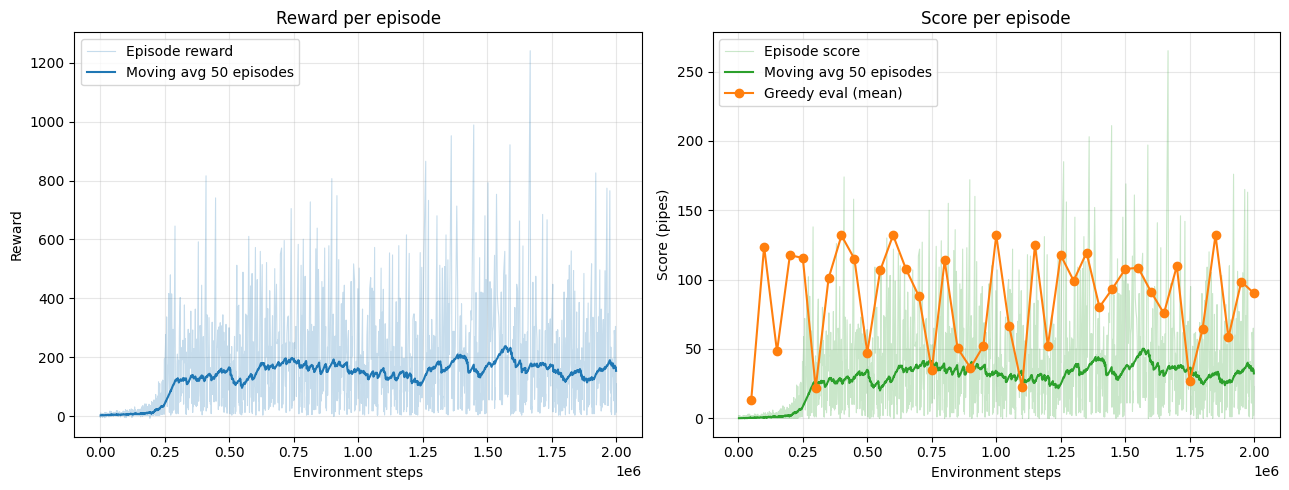

In [4]:
from flappy_rl.plotting import plot_training

plot_training(history, out_path=run_dir / "training_results.png")

## Đánh giá
Điểm holdout dùng seed khác với seed chọn checkpoint.

In [5]:
from IPython.display import Video, display

from flappy_rl.evaluation import evaluate_policy, record_video

best = DQNAgent.from_checkpoint(run_dir / "best.pt", DEVICE)
holdout_env = make_env(MODE)
try:
    holdout = evaluate_policy(best, holdout_env, num_episodes=10, max_steps=10_000, seed=SEED + 20_000)
finally:
    holdout_env.close()
print("Holdout:", holdout)
(run_dir / "holdout.json").write_text(json.dumps({"mean_score": holdout, "episodes": 10}), encoding="utf-8")
record_video(best, run_dir / "gameplay.mp4")
display(Video(str(run_dir / "gameplay.mp4"), embed=True))

Holdout: 193.7
Video: /content/drive/MyDrive/flappy_bird_output/pixel_20261029_074054/gameplay.mp4 | scores [39, 39, 39] | mean 39.00


## Giao diện 3D
Replay chạy cho cả hai chế độ; chạy mạng trực tiếp trong trình duyệt chỉ hỗ trợ `state`.

In [6]:
from flappy_rl.export import export_mlp_weights, record_replay
from flappy_rl.viewer import build_3d_viewer, show_3d

replay = record_replay(best, out_path=run_dir / "replay.json")
weights = export_mlp_weights(best, out_path=run_dir / "weights.json")
display(show_3d(build_3d_viewer(replay, weights, out_path=run_dir / "viewer.html")))

Replay: /content/drive/MyDrive/flappy_bird_output/pixel_20261029_074054/replay.json (659 KB), scores [79, 79, 79]
Skipped weights export: only the state-mode MLP runs in the browser.
Viewer: /content/drive/MyDrive/flappy_bird_output/pixel_20261029_074054/viewer.html (751 KB)


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")
